**Cell 00 · Cell index**

**Cell 00 · Cell index** — each cell is prefixed with `Cell NN · name` (also in cell metadata `cell_label`).

- **01 · Intro**
- **02 · Setup & dependencies**
- **03 · Extract abstract**
- **04 · NLTK tokenization**
- **05 · Syuzhet overview**
- **06 · Syuzhet & NRC scores**
- **07 · Emotions by sentence**
- **08 · Abstract sentiment plots**
- **09 · Full-document extraction overview**
- **10 · pdfplumber & paragraph chunks**
- **11 · Responsibility taxonomy overview**
- **12 · Keyword & regex metric harvest**
- **13 · Semantic retrieval overview**
- **14 · Sentence-transformer search**
- **15 · Responsibility metrics building blocks overview**
- **16 · Building blocks & export**
- **17 · NLP pipeline visualizations overview**
- **18 · NLP pipeline visualization plots**
- **19 · Map chunks to implementation steps**
- **20 · Structured blueprint overview**
- **21 · Build & export responsibility blueprint**
- **22 · Optional Grobid & LLM extraction notes**
- **23 · Table 1 DDDM baseline overview**
- **24 · Table 1 governance column recommendations**


**Cell 01 · Intro**

NLP analysis of **A Practical SAFE-AI Framework for Small and Medium-Sized Enterprises Developing Medical Artificial Intelligence Ethics Policies** (Nemteanu et al.).

This notebook:

1. Extracts and tokenizes the abstract; runs **Syuzhet / NRC** sentiment (via `moodswing`).
2. Parses the full PDF with **layout-aware** `pdfplumber` (and compares to `pypdf`).
3. Harvests **responsibility metrics** language (fairness, transparency, SPAMM, monitoring).
4. Runs **semantic retrieval** over paragraph chunks (`sentence-transformers`).
5. Aligns passages to a **five-step implementation guide** and exports a structured **responsibility blueprint** CSV.

PDF path: `SAFE-AI White Paper - Ethics in Medical AI Usage.pdf` at the repo root (or parent of `NLP/`).


In [41]:
# Cell 02 · Setup & dependencies
from __future__ import annotations

import importlib.util
import json
import re
import subprocess
import sys
from dataclasses import asdict, dataclass
from datetime import datetime
from pathlib import Path

CORE_PACKAGES = ("nltk", "moodswing", "pypdf", "matplotlib", "pandas", "pdfplumber")
OPTIONAL_PACKAGES = ("sentence_transformers",)

missing = [pkg for pkg in CORE_PACKAGES if importlib.util.find_spec(pkg) is None]
if missing:
    print(f"Installing into kernel: {sys.executable}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing, "-q"])

import matplotlib.pyplot as plt
import nltk
import pandas as pd
import pdfplumber
from moodswing import DictionarySentimentAnalyzer
from pypdf import PdfReader

for resource in ("punkt", "punkt_tab"):
    nltk.download(resource, quiet=True)

ROOT = Path.cwd().resolve()
if not (ROOT / "SAFE-AI White Paper - Ethics in Medical AI Usage.pdf").exists():
    ROOT = ROOT.parent

PDF_PATH = ROOT / "SAFE-AI White Paper - Ethics in Medical AI Usage.pdf"
NLP_DIR = ROOT / "NLP" if (ROOT / "NLP").is_dir() else Path.cwd()
OUTPUT_DIR = NLP_DIR / "compiled"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"PDF: {PDF_PATH}")
print(f"Exists: {PDF_PATH.exists()}")
print(f"Outputs: {OUTPUT_DIR}")

HAS_SENTENCE_TRANSFORMERS = importlib.util.find_spec("sentence_transformers") is not None
print(f"sentence_transformers installed: {HAS_SENTENCE_TRANSFORMERS}")


def display_dataframe_full_text(
    df: pd.DataFrame,
    text_column: str | None = "text",
    wrap_columns: list[str] | None = None,
    preview_chars: int | None = None,
) -> None:
    """Render a DataFrame in HTML with pre-wrap; optionally truncate cells for notebook preview."""
    from html import escape
    from IPython.display import HTML, display

    if wrap_columns is None:
        if text_column and text_column in df.columns:
            wrap_columns = [text_column]
        else:
            wrap_columns = [
                c
                for c in df.columns
                if df[c].dtype == object and df[c].astype(str).str.len().max() > 60
            ]
    wrap_set = set(wrap_columns)
    cols = list(df.columns)
    header = "".join(f"<th>{escape(str(c))}</th>" for c in cols)
    body_rows = []

    def _preview(val: str, col: str) -> str:
        if preview_chars is None or col not in wrap_set:
            return val
        if len(val) <= preview_chars:
            return val
        return val[: preview_chars - 1] + "…"

    for _, row in df[cols].iterrows():
        cells = []
        for c in cols:
            val = escape(_preview(str(row[c]), c))
            if c in wrap_set:
                cells.append(
                    f'<td style="white-space:pre-wrap;max-width:960px;vertical-align:top;text-align:left">{val}</td>'
                )
            else:
                cells.append(f"<td style=\"vertical-align:top\">{val}</td>")
        body_rows.append("<tr>" + "".join(cells) + "</tr>")
    html_table = (
        "<style>table.dddm td, table.dddm th { border:1px solid #ccc; padding:6px; font-size:13px; }</style>"
        f"<table class=\"dddm\"><thead><tr>{header}</tr></thead><tbody>{''.join(body_rows)}</tbody></table>"
    )
    display(HTML(html_table))


def write_csv_safe(df: pd.DataFrame, path: Path) -> Path:
    """Write CSV; on Windows file-lock (Excel open), write timestamped fallback."""
    path = Path(path)
    try:
        df.to_csv(path, index=False)
        return path
    except PermissionError:
        alt = path.with_name(f"{path.stem}_{datetime.now():%Y%m%d_%H%M%S}{path.suffix}")
        df.to_csv(alt, index=False)
        print(f"Permission denied: {path} (close in Excel/editor). Wrote {alt}")
        return alt


def write_building_blocks_workbook(
    blocks_df: pd.DataFrame,
    methodology_df: pd.DataFrame,
    xlsx_path: Path,
) -> Path:
    """Write two-sheet xlsx; fallback path if workbook is open in Excel."""
    if importlib.util.find_spec("openpyxl") is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "openpyxl", "-q"])
    xlsx_path = Path(xlsx_path)

    def _write(target: Path) -> None:
        with pd.ExcelWriter(target, engine="openpyxl") as writer:
            blocks_df.to_excel(writer, sheet_name="Building_Blocks", index=False)
            methodology_df.to_excel(writer, sheet_name="NLP_Methodology", index=False)

    try:
        _write(xlsx_path)
        return xlsx_path
    except PermissionError:
        alt = xlsx_path.with_name(f"{xlsx_path.stem}_{datetime.now():%Y%m%d_%H%M%S}{xlsx_path.suffix}")
        _write(alt)
        print(f"Permission denied: {xlsx_path} (close in Excel). Wrote {alt}")
        return alt


PDF: C:\Users\tnewman\Documents\DDDM\SAFE-AI White Paper - Ethics in Medical AI Usage.pdf
Exists: True
Outputs: C:\Users\tnewman\Documents\DDDM\NLP\compiled
sentence_transformers installed: True


**Cell 03 · Extract abstract**

Pull the abstract with `pypdf` using `Abstract` → `Introduction` markers (same as the original notebook).


In [42]:
# Cell 03 · Extract abstract
def extract_abstract(pdf_path: Path, scan_pages: int = 3) -> str:
    """Pull the abstract section from the white paper PDF."""
    reader = PdfReader(str(pdf_path))
    text = " ".join((page.extract_text() or "") for page in reader.pages[:scan_pages])
    text = re.sub(r"\s+", " ", text).strip()

    start = text.lower().find("abstract")
    end = text.lower().find("introduction")
    if start == -1 or end == -1 or end <= start:
        raise ValueError("Could not locate Abstract / Introduction markers in PDF text.")

    return text[start + len("abstract") : end].strip()


abstract = extract_abstract(PDF_PATH)
print(f"Abstract length: {len(abstract):,} characters")
print("\n" + abstract)


Abstract length: 1,383 characters

Artificial intelligence (AI) offers incredible possibilities for patient care, but raises significant ethical issues, such as the potential for bias. Powerful ethical frameworks exist to minimize these issues, but are often developed for academic or regulatory environments and tend to be comprehensive but overly prescriptive, making them difficult to operationalize within fast-paced, resource-constrained environments. We introduce the Scalable Agile Framework for Execution in AI (SAFE-AI) designed to balance ethical rigor with business priorities by embedding ethical oversight into standard Agile-based product development workflows. The framework emphasizes the early establishment of testable acceptance criteria, fairness metrics, and transparency metrics to manage model uncertainty, while also promoting continuous monitoring and re-evaluation of these metrics across the AI lifecycle. A core component of this framework are responsibility metrics using

**Cell 04 · NLTK tokenization**

Tokenize and sentence-split the abstract.


In [43]:
# Cell 04 · NLTK tokenization
tokens = nltk.word_tokenize(abstract)
alpha_tokens = [t for t in tokens if any(ch.isalpha() for ch in t)]
sentences = nltk.sent_tokenize(abstract)

token_summary = pd.DataFrame(
    {
        "metric": ["sentences", "tokens (all)", "tokens (with letters)"],
        "count": [len(sentences), len(tokens), len(alpha_tokens)],
    }
)
display(token_summary)

print("First 40 tokens:")
print(tokens[:40])


,metric,count
0,sentences,7
1,tokens (all),200
2,tokens (with letters),179


First 40 tokens:
['Artificial', 'intelligence', '(', 'AI', ')', 'offers', 'incredible', 'possibilities', 'for', 'patient', 'care', ',', 'but', 'raises', 'significant', 'ethical', 'issues', ',', 'such', 'as', 'the', 'potential', 'for', 'bias', '.', 'Powerful', 'ethical', 'frameworks', 'exist', 'to', 'minimize', 'these', 'issues', ',', 'but', 'are', 'often', 'developed', 'for', 'academic']


**Cell 05 · Syuzhet overview**

Score each abstract sentence with the **Syuzhet** valence lexicon and **NRC** emotions (`moodswing`, same dictionaries as R `syuzhet`).


In [44]:
# Cell 06 · Syuzhet & NRC scores
analyzer = DictionarySentimentAnalyzer()

syuzhet_scores = analyzer.sentence_scores(sentences, method="syuzhet")
nrc_by_sentence = analyzer.nrc_emotions(sentences, language="english")

syuzhet_df = pd.DataFrame({"sentence": sentences, "syuzhet_score": syuzhet_scores})
display(syuzhet_df)

emotion_totals = pd.Series({k: 0.0 for k in nrc_by_sentence[0]})
for row in nrc_by_sentence:
    for emotion, value in row.items():
        emotion_totals[emotion] += value

emotion_totals = emotion_totals.sort_values(ascending=False)
print("\nNRC emotion totals (abstract):")
display(emotion_totals.to_frame("count"))


,sentence,syuzhet_score
0,Artificial intelligence (AI) offers incredible...,3.00
1,Powerful ethical frameworks exist to minimize ...,1.65
2,We introduce the Scalable Agile Framework for ...,1.10
3,The framework emphasizes the early establishme...,2.00
4,A core component of this framework are respons...,1.00
5,This ensures that retraining or tuning activit...,1.25
6,By focusing on the minimum necessary requireme...,2.40



NRC emotion totals (abstract):


,count
positive,21.0
trust,11.0
negative,8.0
fear,6.0
anticipation,3.0
anger,3.0
joy,2.0
disgust,2.0
sadness,1.0
surprise,0.0


**Cell 07 · Emotions by sentence**

Per-sentence NRC emotion counts joined with Syuzhet scores.


In [45]:
# Cell 07 · Emotions by sentence
emotion_by_sentence = pd.DataFrame(nrc_by_sentence)
emotion_by_sentence.insert(0, "sentence_id", range(1, len(sentences) + 1))
emotion_by_sentence.insert(1, "sentence", sentences)
emotion_by_sentence.insert(2, "syuzhet_score", syuzhet_scores)

display(emotion_by_sentence)


,sentence_id,sentence,syuzhet_score,anger,anticipation,disgust,fear,joy,negative,positive,sadness,surprise,trust
0,1,Artificial intelligence (AI) offers incredible...,3.00,1.0,1.0,0.0,1.0,1.0,1.0,3.0,0.0,0.0,1.0
1,2,Powerful ethical frameworks exist to minimize ...,1.65,1.0,1.0,1.0,3.0,1.0,2.0,4.0,0.0,0.0,2.0
2,3,We introduce the Scalable Agile Framework for ...,1.10,1.0,0.0,1.0,2.0,0.0,3.0,4.0,1.0,0.0,2.0
3,4,The framework emphasizes the early establishme...,2.00,0.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0,2.0
4,5,A core component of this framework are respons...,1.00,0.0,1.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,2.0
5,6,This ensures that retraining or tuning activit...,1.25,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
6,7,By focusing on the minimum necessary requireme...,2.40,0.0,0.0,0.0,0.0,0.0,1.0,4.0,0.0,0.0,2.0


**Cell 08 · Abstract sentiment plots**

Quick visual summary of abstract tone.


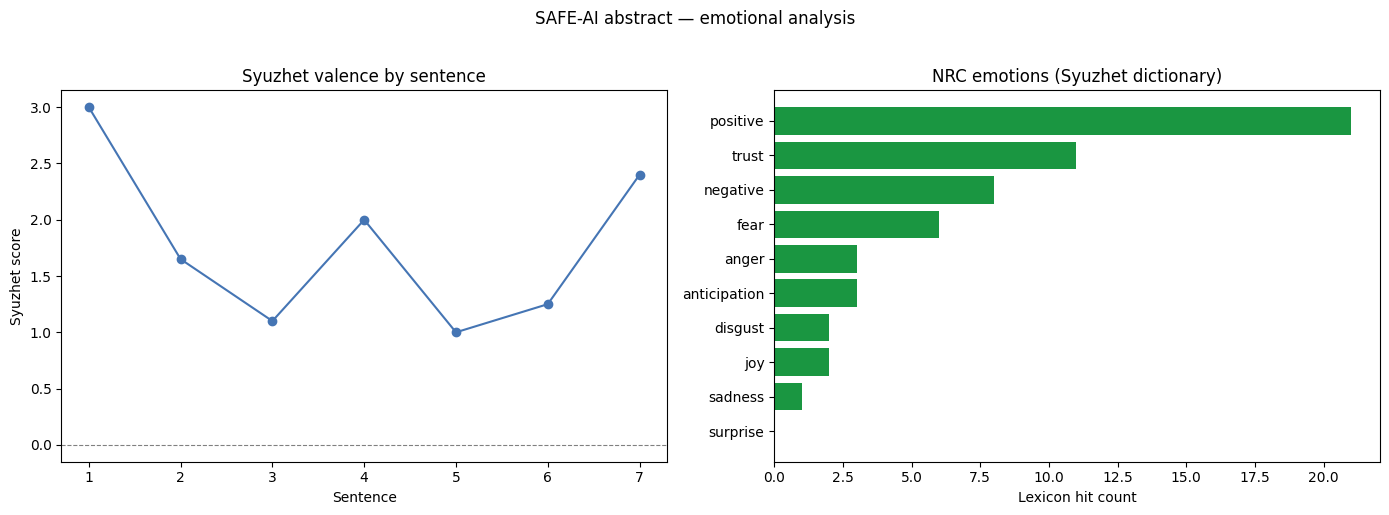

In [46]:
# Cell 08 · Abstract sentiment plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(range(1, len(syuzhet_scores) + 1), syuzhet_scores, marker="o", color="#4575b4")
axes[0].axhline(0, color="gray", linewidth=0.8, linestyle="--")
axes[0].set_xlabel("Sentence")
axes[0].set_ylabel("Syuzhet score")
axes[0].set_title("Syuzhet valence by sentence")
axes[0].set_xticks(range(1, len(syuzhet_scores) + 1))

emotion_plot = emotion_totals.sort_values(ascending=True)
axes[1].barh(emotion_plot.index, emotion_plot.values, color="#1a9641")
axes[1].set_xlabel("Lexicon hit count")
axes[1].set_title("NRC emotions (Syuzhet dictionary)")

fig.suptitle("SAFE-AI abstract — emotional analysis", y=1.02)
fig.tight_layout()
plt.show()


**Cell 09 · Full-document extraction overview**

**Layout-aware extraction:** `pdfplumber` preserves page breaks and often handles multi-column PDFs better than plain `pypdf` text merge.

We build **paragraph chunks** for downstream keyword harvest and semantic search.


In [47]:
# Cell 10 · pdfplumber & paragraph chunks
def extract_full_text_pypdf(pdf_path: Path) -> str:
    reader = PdfReader(str(pdf_path))
    pages = [(i + 1, (p.extract_text() or "")) for i, p in enumerate(reader.pages)]
    return pages


def extract_full_text_pdfplumber(pdf_path: Path) -> list[tuple[int, str]]:
    pages: list[tuple[int, str]] = []
    with pdfplumber.open(pdf_path) as pdf:
        for i, page in enumerate(pdf.pages, start=1):
            pages.append((i, page.extract_text() or ""))
    return pages


pypdf_pages = extract_full_text_pypdf(PDF_PATH)
plumber_pages = extract_full_text_pdfplumber(PDF_PATH)

pypdf_chars = sum(len(t) for _, t in pypdf_pages)
plumber_chars = sum(len(t) for _, t in plumber_pages)

display(
    pd.DataFrame(
        {
            "extractor": ["pypdf", "pdfplumber"],
            "pages": [len(pypdf_pages), len(plumber_pages)],
            "characters": [pypdf_chars, plumber_chars],
        }
    )
)

# Prefer pdfplumber text; fall back to pypdf per page when a page is empty.
merged_pages: list[tuple[int, str]] = []
for i in range(max(len(pypdf_pages), len(plumber_pages))):
    page_num = i + 1
    pt = plumber_pages[i][1] if i < len(plumber_pages) else ""
    if len(pt.strip()) < 40 and i < len(pypdf_pages):
        pt = pypdf_pages[i][1]
    merged_pages.append((page_num, pt))

full_text = "\n".join(t for _, t in merged_pages)
full_text = re.sub(r"[ \t]+", " ", full_text)
full_text = re.sub(r"\n{3,}", "\n\n", full_text).strip()


def paragraph_chunks(pages: list[tuple[int, str]], min_chars: int = 120) -> pd.DataFrame:
    rows = []
    for page_num, page_text in pages:
        page_text = re.sub(r"[ \t]+", " ", page_text or "")
        for para in re.split(r"\n\s*\n|\n(?=[A-Z])", page_text):
            para = para.strip()
            if len(para) < min_chars:
                continue
            rows.append({"page": page_num, "paragraph": para, "char_len": len(para)})
    return pd.DataFrame(rows)


chunks_df = paragraph_chunks(merged_pages)
print(f"Paragraph chunks: {len(chunks_df):,}")
display(chunks_df.head(3)[["page", "char_len", "paragraph"]])


,extractor,pages,characters
0,pypdf,31,104833
1,pdfplumber,31,81955


Paragraph chunks: 168


,page,char_len,paragraph
0,1,191,"Pettine3,4,*\n1Nemsee, LLC., Escondido, Califo..."
1,1,130,"Utah\n4Department of Psychiatry, The Universit..."
2,1,1383,Artificial intelligence (AI) offers incredible...


**Cell 11 · Responsibility taxonomy overview**

Nemteanu et al. frame **responsibility metrics** as testable Agile acceptance criteria in two technical buckets:

| Category | Role |
|----------|------|
| **Fairness metrics** | Statistical bias detection / mitigation across protected subgroups |
| **Transparency metrics** | Explain uncertainty (e.g. **SPAMM** — scenario-based probability analogy mapping) |

The cells below regex-scan the full paper for these themes and list candidate **actionable** phrases.


In [48]:
# Cell 12 · Keyword & regex metric harvest
RESPONSIBILITY_THEMES = {
    "fairness": [
        r"fairness\s+metric",
        r"protected\s+(attribute|subgroup|group)",
        r"disparate\s+impact",
        r"false\s+negative",
        r"statistical\s+bias",
        r"sub[- ]population",
    ],
    "transparency": [
        r"transparency\s+metric",
        r"interpretab",
        r"explainab",
        r"SPAMM",
        r"scenario[- ]based",
        r"probability\s+analogy",
        r"SHAP|LIME|feature\s+importance",
    ],
    "agile_process": [
        r"ECCOLA",
        r"user\s+stor",
        r"sprint",
        r"acceptance\s+criteria",
        r"Agile",
    ],
    "engineering": [
        r"AII\s+contract",
        r"inference\s+engine",
        r"product\s+engine",
        r"re[- ]train",
        r"hyperparameter",
    ],
    "monitoring": [
        r"concept\s+drift",
        r"data\s+drift",
        r"bias\s+drift",
        r"monitor",
        r"post[- ]deployment",
    ],
}

compiled = re.compile("|".join(f"(?:{p})" for patterns in RESPONSIBILITY_THEMES.values() for p in patterns), re.I)


def harvest_theme_hits(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for theme, patterns in RESPONSIBILITY_THEMES.items():
        for pat in patterns:
            rx = re.compile(pat, re.I)
            for _, row in df.iterrows():
                if rx.search(row["paragraph"]):
                    rows.append(
                        {
                            "theme": theme,
                            "pattern": pat,
                            "page": row["page"],
                            "paragraph": row["paragraph"],
                            "snippet": row["paragraph"][:280] + ("…" if len(row["paragraph"]) > 280 else ""),
                        }
                    )
    out = pd.DataFrame(rows)
    if out.empty:
        return out
    return out.drop_duplicates(subset=["theme", "page", "paragraph"]).sort_values(["theme", "page"])


theme_hits = harvest_theme_hits(chunks_df)
print(f"Theme hits: {len(theme_hits):,}")
display(theme_hits.groupby("theme").size().rename("hit_count").to_frame())

display(theme_hits.head(12))

keyword_counts = {kw: len(re.findall(re.escape(kw), full_text, re.I)) for kw in [
    "fairness", "transparency", "responsibility", "SPAMM", "ECCOLA", "drift", "AII"
]}
display(pd.Series(keyword_counts, name="global_count").sort_values(ascending=False).to_frame())


Theme hits: 70


,hit_count
theme,
agile_process,20
engineering,12
fairness,6
monitoring,13
transparency,19


,theme,pattern,page,paragraph,snippet
53,agile_process,acceptance\s+criteria,1,Artificial intelligence (AI) offers incredible...,Artificial intelligence (AI) offers incredible...
63,agile_process,Agile,4,Framework creation unfolded over 20 weeks (Jan...,Framework creation unfolded over 20 weeks (Jan...
48,agile_process,user\s+stor,5,We present the Scalable Agile Framework for Ex...,We present the Scalable Agile Framework for Ex...
54,agile_process,acceptance\s+criteria,7,A comprehensive regulatory review should be co...,A comprehensive regulatory review should be co...
43,agile_process,ECCOLA,8,"Building on this foundation, Vakkuri et al. (2...","Building on this foundation, Vakkuri et al. (2..."
44,agile_process,ECCOLA,8,"By aligning ECCOLA cards to user stories, team...","By aligning ECCOLA cards to user stories, team..."
45,agile_process,ECCOLA,8,"In this way, ECCOLA serves as a lightweight bu...","In this way, ECCOLA serves as a lightweight bu..."
49,agile_process,user\s+stor,8,This phase begins with breaking down high-leve...,This phase begins with breaking down high-leve...
52,agile_process,sprint,9,This approach helps convert abstract ethical p...,This approach helps convert abstract ethical p...
55,agile_process,acceptance\s+criteria,12,Acceptance criteria define the conditions that...,Acceptance criteria define the conditions that...


,global_count
transparency,30
fairness,27
responsibility,17
drift,8
ECCOLA,7
SPAMM,4
AII,4


**Cell 13 · Semantic retrieval overview**

**Semantic metric filtering:** embed paragraph chunks and retrieve the passages closest to implementation-oriented queries (fairness thresholds, SPAMM, drift monitoring, AII contract).

Install (first run may download ~400MB model weights):

```bash
pip install sentence-transformers
```

Default model: `all-MiniLM-L6-v2` (fast). Set `EMBED_MODEL` to a scientific encoder (e.g. `NeuML/pubmedbert-base-embeddings`) if preferred.


In [49]:
# Cell 14 · Sentence-transformer search
SEMANTIC_QUERIES = [
    ("fairness", "fairness metrics statistical bias false negative rate subgroups thresholds"),
    ("transparency", "transparency metrics SPAMM scenario-based probability analogy mapping uncertainty"),
    ("agile", "ECCOLA user stories sprint acceptance criteria responsibility metrics agile"),
    ("engineering", "AII contract inference engine product engine API version control"),
    ("monitoring", "concept drift data drift bias drift post-deployment monitoring re-evaluation"),
]

TOP_K = 5
EMBED_MODEL = "all-MiniLM-L6-v2"
INSTALL_SEMANTIC = True

semantic_results: pd.DataFrame | None = None

if not HAS_SENTENCE_TRANSFORMERS and INSTALL_SEMANTIC:
    print("Installing sentence-transformers (one-time)…")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "sentence-transformers", "-q"])
    HAS_SENTENCE_TRANSFORMERS = importlib.util.find_spec("sentence_transformers") is not None

if HAS_SENTENCE_TRANSFORMERS:
    import numpy as np
    from sentence_transformers import SentenceTransformer

    model = SentenceTransformer(EMBED_MODEL)
    corpus = chunks_df["paragraph"].tolist()
    corpus_emb = model.encode(corpus, normalize_embeddings=True, show_progress_bar=True)

    rows = []
    for query_label, query_text in SEMANTIC_QUERIES:
        q_emb = model.encode([query_text], normalize_embeddings=True)[0]
        scores = np.dot(corpus_emb, q_emb)
        top_idx = np.argsort(scores)[::-1][:TOP_K]
        for rank, idx in enumerate(top_idx, start=1):
            rows.append(
                {
                    "query_theme": query_label,
                    "rank": rank,
                    "score": float(scores[idx]),
                    "page": int(chunks_df.iloc[idx]["page"]),
                    "paragraph": corpus[idx],
                }
            )
    semantic_results = pd.DataFrame(rows)
    display(semantic_results[["query_theme", "rank", "score", "page"]])
    for q in semantic_results["query_theme"].unique():
        print(f"\n=== Top passage: {q} ===")
        top = semantic_results[semantic_results["query_theme"] == q].iloc[0]
        print(f"(page {top['page']}, score={top['score']:.3f})")
        print(top["paragraph"][:600] + ("…" if len(top["paragraph"]) > 600 else ""))
else:
    print("sentence-transformers unavailable — skip semantic search or set INSTALL_SEMANTIC=True.")


Batches: 100%|██████████| 6/6 [00:02<00:00,  2.64it/s]


,query_theme,rank,score,page
0,fairness,1,0.707000,13
1,fairness,2,0.569696,13
2,fairness,3,0.494571,24
3,fairness,4,0.494446,28
4,fairness,5,0.465445,12
5,transparency,1,0.688957,13
6,transparency,2,0.575146,14
7,transparency,3,0.521659,27
8,transparency,4,0.480030,23
9,transparency,5,0.466084,15



=== Top passage: fairness ===
(page 13, score=0.707)
In practice, fairness metrics are used to detect and mitigate disparate impacts—ensuring
that one group or class (e.g., based on race, gender, age, or geography) is not
disproportionately harmed or excluded compared to others. This may involve evaluating
performance across subgroups, measuring disparities in false positives or negatives, or
assessing equal access to beneficial outcomes. The goal is not only to identify statistical
imbalance, but to actively choose metrics that reflect the ethical priorities and risk
tolerances of the system’s intended users and affected populations.

=== Top passage: transparency ===
(page 13, score=0.689)
Transparency Metrics: Define metrics that focus on ensuring that AI model predictions are
interpretable, explainable, and actionable by end users. One technique used in this
framework is a scenario-based probability analogy mapping method - a structured
approach to communicating AI predictions by 

**Cell 15 · Responsibility metrics building blocks overview**

In Nemteanu et al., **responsibility metrics** are not a single score — they are **testable Agile acceptance criteria** that operationalize ethics across the ML lifecycle. Cells **16–19** build the generalized **building blocks** export, pipeline visualizations, and five-step passage alignment.

### Generalized building blocks (paper → any project)

| Block | Generalized intent | Primary tools / methods in SAFE-AI |
|---|---|---|
| **Scope gate** | Decide metric depth from stakeholder impact (internal automation vs patient-facing) | DDDM / risk tiering; discovery interviews |
| **Backlog translation** | Turn ethics themes into sprint-sized **user stories** and **acceptance criteria** | **ECCOLA** cards; **RESOLVEDD** alignment; standard Agile |
| **Fairness metrics** | Define protected subgroups and quantitative thresholds (e.g. FN-rate variance caps) | Subgroup evaluation, confusion matrices by cohort; fairness test checklists |
| **Transparency metrics** | Explain uncertainty to non-technical stakeholders, not only developers | **SPAMM** (scenario-based probability analogy mapping); FP/FN **cost matrix**; SHAP/LIME as *supplement* only |
| **Engineering split** | Decouple deterministic product code from probabilistic inference | **Product Engine (PE)** vs **Inference Engine (IE)**; **AI Integration (AII)** with versioned I/O contract |
| **Change control** | Treat retrain / tuning as a new validation cycle | Re-run fairness + transparency checkmarks before release |
| **Monitoring** | Detect degradation of responsibility metrics in production | Concept, data, integrity, and **bias drift** monitoring with alerts |

### Five-step implementation map (Cell 19)

1. Scoping & task alignment (discovery) — blocks **Scope gate**, **Backlog translation**
2. Formulating fairness metrics — block **Fairness metrics**
3. Transparency & interpretability — block **Transparency metrics** (**SPAMM**)
4. System implementation & architecture — blocks **Engineering split**, **Change control**
5. Post-deployment monitoring — block **Monitoring**

### How `responsibility_building_blocks.csv` is constructed (NLP pipeline)

The exported CSV is a **hybrid** artifact: generalized rows are **authored from the SAFE-AI framework** (Cell 16 `BUILDING_BLOCK_SPECS`), and NLP **links each row to evidence** in the PDF (`paper_page`, `paper_excerpt`). Abstract sentiment (Cells 04–08) is **not** used for this table.

| Stage | Tool / method | Role for building blocks |
|---|---|---|
| **1. Layout-aware extraction** | `pdfplumber` (+ `pypdf` fallback per page) | Turns the white paper PDF into page-level text (Cell 10). |
| **2. Segmentation** | Regex paragraph chunking (`chunks_df`) | Splits text into ~120+ character units with page numbers — the retrieval corpus. |
| **3. Thematic pattern matching** | Compiled regex over `RESPONSIBILITY_THEMES` (Cell 12) | Labels paragraphs as `fairness`, `transparency`, `agile_process`, `engineering`, or `monitoring`; output **`theme_hits`**. |
| **4. Evidence attachment** | `_first_paper_hit()` in Cell 16 | For each building block: (a) take the first `theme_hits` row matching `nlp_themes`, else (b) scan `chunks_df` for substring matches on `paper_terms` (e.g. ECCOLA, SPAMM, AII). |
| **5. Export** | `pandas` + `openpyxl` | Writes `responsibility_building_blocks.xlsx` (sheet **Building_Blocks** + sheet **NLP_Methodology**) and `responsibility_building_blocks.csv` (data only). |

**Related NLP (same notebook, different outputs):** Cell 14 **`sentence-transformers`** (`all-MiniLM-L6-v2`) embeds chunks for semantic query ranking (`semantic_results`) and for the **five-step `step_alignment`** table in Cell 19 — it does **not** auto-generate the seven generalized block definitions; it validates *which passage* best supports each implementation phase.

**Interpretation:** Columns `generalized_template` and `tools_and_methods` are **portable policy templates** (usable on any medical-AI project). Columns `paper_page` and `paper_excerpt` are **traceability** from NLP retrieval — re-run Cells 10 → 12 → 16 → 18 after PDF or regex changes to refresh evidence and charts.



In [50]:
# Cell 16 · Building blocks & export
BUILDING_BLOCK_SPECS: list[dict] = [
    {
        "block_id": "BB1",
        "building_block": "Scope gate",
        "generalized_template": (
            "Classify the use case by stakeholder impact (internal vs patient/end-user) and "
            "select the minimum responsibility-metric suite for that tier."
        ),
        "tools_and_methods": "DDDM / Table 1 risk tiering; discovery interviews; SAFE-AI scoping",
        "implementation_step": "1_discovery",
        "nlp_themes": ("agile_process",),
        "paper_terms": ("stakeholder", "acceptance criteria", "minimum necessary"),
    },
    {
        "block_id": "BB2",
        "building_block": "Backlog translation",
        "generalized_template": (
            "Convert each ethics theme into Agile user stories with testable acceptance criteria "
            "(time-boxed sprint tickets)."
        ),
        "tools_and_methods": "ECCOLA card deck; RESOLVEDD process alignment; Scrum/Kanban backlog",
        "implementation_step": "1_discovery",
        "nlp_themes": ("agile_process",),
        "paper_terms": ("ECCOLA", "user stor", "RESOLVEDD", "responsibility metric"),
    },
    {
        "block_id": "BB3",
        "building_block": "Fairness metrics",
        "generalized_template": (
            "Name protected subgroups; set quantitative thresholds (e.g., max FN-rate variance across "
            "cohorts); gate release on passing subgroup checks."
        ),
        "tools_and_methods": (
            "Subgroup confusion matrices; fairness metric checklist; statistical parity / error-rate "
            "balance tests (paper: detect and mitigate statistical bias)"
        ),
        "implementation_step": "2_fairness",
        "nlp_themes": ("fairness",),
        "paper_terms": ("fairness metric", "subgroup", "false negative", "disparate"),
    },
    {
        "block_id": "BB4",
        "building_block": "Transparency metrics",
        "generalized_template": (
            "Document what a wrong prediction means operationally (FP/FN cost matrix) and explain "
            "model uncertainty with stakeholder-facing scenarios—not developer-only feature plots."
        ),
        "tools_and_methods": (
            "SPAMM (scenario-based probability analogy mapping); FP/FN impact matrix; "
            "SHAP/LIME optional for engineers only"
        ),
        "implementation_step": "3_transparency",
        "nlp_themes": ("transparency",),
        "paper_terms": ("SPAMM", "scenario", "transparency metric", "uncertainty"),
    },
    {
        "block_id": "BB5",
        "building_block": "Engineering split",
        "generalized_template": (
            "Maintain Product Engine (deterministic UI/DB) separately from Inference Engine (ML); "
            "integrate only through a version-controlled AI Integration (AII) I/O contract."
        ),
        "tools_and_methods": "Product Engine (PE); Inference Engine (IE); AII contract; API schema versioning",
        "implementation_step": "4_engineering",
        "nlp_themes": ("engineering",),
        "paper_terms": ("Product Engine", "Inference Engine", "AII", "AI Integration"),
    },
    {
        "block_id": "BB6",
        "building_block": "Change control",
        "generalized_template": (
            "Treat every retrain, hyperparameter change, or pipeline edit as a new cycle—re-run "
            "fairness and transparency acceptance criteria before production."
        ),
        "tools_and_methods": "CI/CD gates; metric regression suite; lightweight ethics review checklist",
        "implementation_step": "4_engineering",
        "nlp_themes": ("engineering", "agile_process"),
        "paper_terms": ("retrain", "tuning", "re-evaluat", "hyperparameter"),
    },
    {
        "block_id": "BB7",
        "building_block": "Monitoring",
        "generalized_template": (
            "Automate alerts for concept drift, data drift, data integrity failures, and bias drift "
            "that erode fairness/transparency metrics over time."
        ),
        "tools_and_methods": "Production monitoring; drift detectors; scheduled metric re-evaluation",
        "implementation_step": "5_monitoring",
        "nlp_themes": ("monitoring",),
        "paper_terms": ("drift", "monitor", "post-deployment", "continuous"),
    },
]


def _first_paper_hit(themes: tuple[str, ...], terms: tuple[str, ...]) -> tuple[int | None, str]:
    """Return (page, paragraph) from theme_hits or keyword scan on chunks."""
    if "theme_hits" in globals() and not theme_hits.empty:
        subset = theme_hits[theme_hits["theme"].isin(themes)]
        if not subset.empty:
            row = subset.iloc[0]
            return int(row["page"]), str(row["paragraph"])
    if "chunks_df" in globals():
        for _, row in chunks_df.iterrows():
            low = row["paragraph"].lower()
            if any(t.lower() in low for t in terms):
                return int(row["page"]), str(row["paragraph"])
    return None, ""


block_rows = []
for spec in BUILDING_BLOCK_SPECS:
    page, para = _first_paper_hit(spec["nlp_themes"], spec["paper_terms"])
    block_rows.append(
        {
            **spec,
            "paper_page": page,
            "paper_excerpt": para,
        }
    )

responsibility_building_blocks = pd.DataFrame(block_rows)
block_cols = [
    "block_id",
    "building_block",
    "generalized_template",
    "tools_and_methods",
    "implementation_step",
    "paper_page",
]
print("Responsibility metric building blocks (generalized + tools):")
display_dataframe_full_text(
    responsibility_building_blocks[block_cols + ["paper_excerpt"]],
    wrap_columns=["generalized_template", "tools_and_methods", "paper_excerpt"],
    preview_chars=220,
)

NLP_METHODOLOGY_STEPS: list[dict] = [
    {
        "step_number": 0,
        "step_name": "Overview",
        "process_description": (
            "The Building_Blocks sheet is a hybrid artifact: generalized rows come from BUILDING_BLOCK_SPECS "
            "(structured reading of Nemteanu et al.), and NLP attaches paper_page and paper_excerpt for traceability. "
            "Abstract tokenization and Syuzhet/NRC sentiment (Cells 04–08) are not inputs to this export."
        ),
        "nlp_tools_used": "(metadata — no tools)",
    },
    {
        "step_number": 1,
        "step_name": "Layout-aware extraction",
        "process_description": (
            "Extract plain text from the SAFE-AI PDF page by page. Prefer pdfplumber for layout; fall back to "
            "pypdf when a page returns little or no text. Merged page text feeds all downstream chunking and search."
        ),
        "nlp_tools_used": "pdfplumber; pypdf (PdfReader); Python re (whitespace normalize)",
    },
    {
        "step_number": 2,
        "step_name": "Segmentation (paragraph chunks)",
        "process_description": (
            "Split each page into paragraph-level units (minimum ~120 characters) with page numbers. "
            "This chunks_df corpus is the unit of retrieval for regex hits, keyword fallback, and semantic search."
        ),
        "nlp_tools_used": "Python re (paragraph split); pandas (chunks_df)",
    },
    {
        "step_number": 3,
        "step_name": "Thematic pattern matching",
        "process_description": (
            "Apply RESPONSIBILITY_THEMES regex groups (fairness, transparency, agile_process, engineering, monitoring) "
            "across every chunk. Deduplicate hits by theme, page, and full paragraph to produce theme_hits."
        ),
        "nlp_tools_used": "Python re (compiled patterns); pandas (theme_hits)",
    },
    {
        "step_number": 4,
        "step_name": "Generalized block authoring",
        "process_description": (
            "Define seven portable building blocks (scope gate through monitoring) with generalized_template and "
            "tools_and_methods (ECCOLA, SPAMM, PE/IE/AII, etc.). This step encodes framework semantics; it is not "
            "automatically mined from the PDF."
        ),
        "nlp_tools_used": "BUILDING_BLOCK_SPECS (curated spec in Cell 16); pandas",
    },
    {
        "step_number": 5,
        "step_name": "Evidence attachment",
        "process_description": (
            "For each block, _first_paper_hit() selects paper_page and paper_excerpt: (1) first theme_hits row "
            "matching nlp_themes, else (2) first chunks_df paragraph containing any paper_terms substring "
            "(e.g. ECCOLA, SPAMM, Product Engine)."
        ),
        "nlp_tools_used": "theme_hits; chunks_df; Python str substring search; _first_paper_hit()",
    },
    {
        "step_number": 6,
        "step_name": "Export",
        "process_description": (
            "Write responsibility_building_blocks.xlsx with two sheets: Building_Blocks (full table including "
            "paper_excerpt) and NLP_Methodology (this numbered process). Also write building_blocks-only CSV."
        ),
        "nlp_tools_used": "pandas.DataFrame.to_csv; pandas.ExcelWriter; openpyxl",
    },
    {
        "step_number": 7,
        "step_name": "Related — semantic step alignment (same notebook)",
        "process_description": (
            "Optional: sentence-transformers embeds chunks and ranks passages for the five-step step_alignment table "
            "in this cell. Does not generate the seven building-block definitions; complements regex evidence."
        ),
        "nlp_tools_used": "sentence-transformers (all-MiniLM-L6-v2); numpy (cosine via dot product); pandas",
    },
]

nlp_methodology_df = pd.DataFrame(NLP_METHODOLOGY_STEPS)

blocks_csv = write_csv_safe(
    responsibility_building_blocks,
    OUTPUT_DIR / "responsibility_building_blocks.csv",
)
blocks_xlsx = write_building_blocks_workbook(
    responsibility_building_blocks,
    nlp_methodology_df,
    OUTPUT_DIR / "responsibility_building_blocks.xlsx",
)
print(f"Wrote {blocks_csv}")
print(f"Wrote {blocks_xlsx} (sheets: Building_Blocks, NLP_Methodology)")


Responsibility metric building blocks (generalized + tools):


block_id,building_block,generalized_template,tools_and_methods,implementation_step,paper_page,paper_excerpt
BB1,Scope gate,Classify the use case by stakeholder impact (internal vs patient/end-user) and select the minimum responsibility-metric suite for that tier.,DDDM / Table 1 risk tiering; discovery interviews; SAFE-AI scoping,1_discovery,1,"Artificial intelligence (AI) offers incredible possibilities for patient care, but raises significant ethical issues, such as the potential for bias. Powerful ethical frameworks exist to minimize these issues, but are o…"
BB2,Backlog translation,Convert each ethics theme into Agile user stories with testable acceptance criteria (time-boxed sprint tickets).,ECCOLA card deck; RESOLVEDD process alignment; Scrum/Kanban backlog,1_discovery,1,"Artificial intelligence (AI) offers incredible possibilities for patient care, but raises significant ethical issues, such as the potential for bias. Powerful ethical frameworks exist to minimize these issues, but are o…"
BB3,Fairness metrics,"Name protected subgroups; set quantitative thresholds (e.g., max FN-rate variance across cohorts); gate release on passing subgroup checks.",Subgroup confusion matrices; fairness metric checklist; statistical parity / error-rate balance tests (paper: detect and mitigate statistical bias),2_fairness,1,"Artificial intelligence (AI) offers incredible possibilities for patient care, but raises significant ethical issues, such as the potential for bias. Powerful ethical frameworks exist to minimize these issues, but are o…"
BB4,Transparency metrics,Document what a wrong prediction means operationally (FP/FN cost matrix) and explain model uncertainty with stakeholder-facing scenarios—not developer-only feature plots.,SPAMM (scenario-based probability analogy mapping); FP/FN impact matrix; SHAP/LIME optional for engineers only,3_transparency,1,"Artificial intelligence (AI) offers incredible possibilities for patient care, but raises significant ethical issues, such as the potential for bias. Powerful ethical frameworks exist to minimize these issues, but are o…"
BB5,Engineering split,Maintain Product Engine (deterministic UI/DB) separately from Inference Engine (ML); integrate only through a version-controlled AI Integration (AII) I/O contract.,Product Engine (PE); Inference Engine (IE); AII contract; API schema versioning,4_engineering,6,"The SAFE-AI framework is not a one-time gate. It is designed to be re-entered at any point in the development lifecycle whenever changes occur that could materially affect the behavior, fairness, or transparency of the …"
BB6,Change control,"Treat every retrain, hyperparameter change, or pipeline edit as a new cycle—re-run fairness and transparency acceptance criteria before production.",CI/CD gates; metric regression suite; lightweight ethics review checklist,4_engineering,1,"Artificial intelligence (AI) offers incredible possibilities for patient care, but raises significant ethical issues, such as the potential for bias. Powerful ethical frameworks exist to minimize these issues, but are o…"
BB7,Monitoring,"Automate alerts for concept drift, data drift, data integrity failures, and bias drift that erode fairness/transparency metrics over time.",Production monitoring; drift detectors; scheduled metric re-evaluation,5_monitoring,1,"Artificial intelligence (AI) offers incredible possibilities for patient care, but raises significant ethical issues, such as the potential for bias. Powerful ethical frameworks exist to minimize these issues, but are o…"


Permission denied: C:\Users\tnewman\Documents\DDDM\NLP\compiled\responsibility_building_blocks.xlsx (close in Excel). Wrote C:\Users\tnewman\Documents\DDDM\NLP\compiled\responsibility_building_blocks_20261026_122301.xlsx
Wrote C:\Users\tnewman\Documents\DDDM\NLP\compiled\responsibility_building_blocks.csv
Wrote C:\Users\tnewman\Documents\DDDM\NLP\compiled\responsibility_building_blocks_20261026_122301.xlsx (sheets: Building_Blocks, NLP_Methodology)


**Cell 17 · NLP pipeline visualizations overview**

Charts for the path **PDF → chunks → regex `theme_hits` → `_first_paper_hit()` → building blocks export** (Cell 16). Confirms volume and page spread of evidence before five-step alignment (Cell 19).


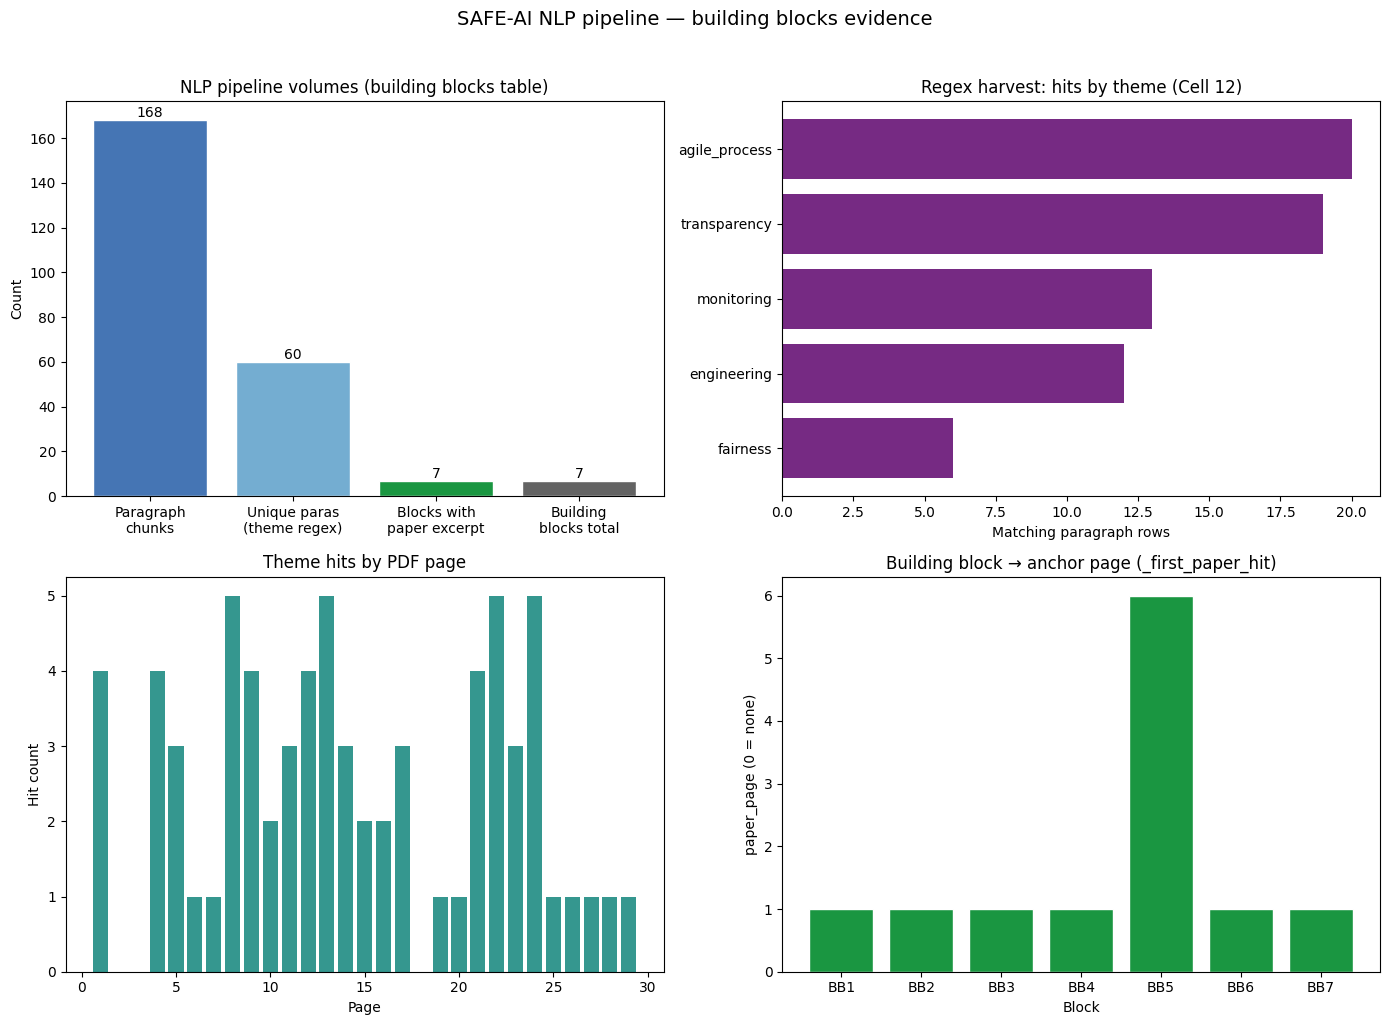

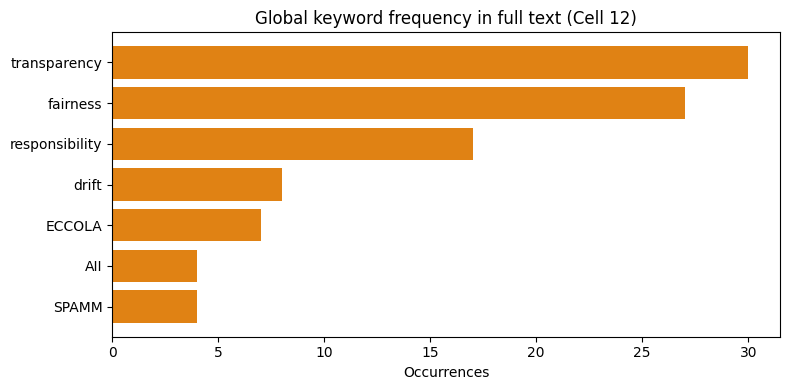

In [51]:
# Cell 18 · NLP pipeline visualization plots
import numpy as np

n_chunks = len(chunks_df)
if theme_hits.empty:
    n_hit_paragraphs = 0
    theme_counts = pd.Series(dtype=int)
else:
    n_hit_paragraphs = theme_hits.drop_duplicates(subset=["paragraph"]).shape[0]
    theme_counts = theme_hits.groupby("theme").size().sort_values(ascending=True)

n_blocks = len(responsibility_building_blocks)
has_excerpt = responsibility_building_blocks["paper_excerpt"].astype(str).str.strip().ne("")
n_with_evidence = int(has_excerpt.sum())

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# --- Panel A: pipeline funnel ---
funnel_labels = [
    "Paragraph\nchunks",
    "Unique paras\n(theme regex)",
    "Blocks with\npaper excerpt",
    "Building\nblocks total",
]
funnel_vals = [n_chunks, n_hit_paragraphs, n_with_evidence, n_blocks]
colors_f = ["#4575b4", "#74add1", "#1a9641", "#636363"]
bars = axes[0, 0].bar(funnel_labels, funnel_vals, color=colors_f, edgecolor="white")
axes[0, 0].set_title("NLP pipeline volumes (building blocks table)")
axes[0, 0].set_ylabel("Count")
for b, v in zip(bars, funnel_vals):
    axes[0, 0].text(b.get_x() + b.get_width() / 2, v, str(v), ha="center", va="bottom", fontsize=10)

# --- Panel B: theme_hits by theme ---
if theme_counts.empty:
    axes[0, 1].text(0.5, 0.5, "No theme_hits", ha="center", va="center")
    axes[0, 1].set_axis_off()
else:
    axes[0, 1].barh(theme_counts.index, theme_counts.values, color="#762a83")
    axes[0, 1].set_title("Regex harvest: hits by theme (Cell 12)")
    axes[0, 1].set_xlabel("Matching paragraph rows")

# --- Panel C: hits across PDF pages ---
if theme_hits.empty:
    axes[1, 0].text(0.5, 0.5, "No theme_hits", ha="center", va="center")
    axes[1, 0].set_axis_off()
else:
    page_counts = theme_hits.groupby("page").size()
    axes[1, 0].bar(page_counts.index, page_counts.values, width=0.8, color="#35978f")
    axes[1, 0].set_title("Theme hits by PDF page")
    axes[1, 0].set_xlabel("Page")
    axes[1, 0].set_ylabel("Hit count")

# --- Panel D: evidence page per building block ---
bb = responsibility_building_blocks.copy()
bb["has_evidence"] = has_excerpt.values
pages = bb["paper_page"].fillna(-1).astype(int)
bar_colors = ["#1a9641" if ok else "#d73027" for ok in bb["has_evidence"]]
axes[1, 1].bar(bb["block_id"], pages.replace(-1, 0), color=bar_colors, edgecolor="white")
axes[1, 1].set_title("Building block → anchor page (_first_paper_hit)")
axes[1, 1].set_xlabel("Block")
axes[1, 1].set_ylabel("paper_page (0 = none)")
for x, (_, row) in enumerate(bb.iterrows()):
    if not row["has_evidence"]:
        axes[1, 1].text(x, 0.5, "no hit", ha="center", fontsize=8, rotation=90)

fig.suptitle("SAFE-AI NLP pipeline — building blocks evidence", y=1.02, fontsize=14)
fig.tight_layout()
plt.show()

try:
    kw = pd.Series(keyword_counts).sort_values(ascending=True)
    fig2, ax2 = plt.subplots(figsize=(8, 4))
    ax2.barh(kw.index.astype(str), kw.values, color="#e08214")
    ax2.set_title("Global keyword frequency in full text (Cell 12)")
    ax2.set_xlabel("Occurrences")
    fig2.tight_layout()
    plt.show()
except NameError:
    print("Re-run Cell 12 to enable the keyword frequency chart.")


In [52]:
# Cell 19 · Map chunks to implementation steps
IMPLEMENTATION_STEPS = {
    "1_discovery": "stakeholder impact external users ECCOLA user stories agile discovery scoping",
    "2_fairness": "protected subgroups baseline thresholds false negative variance disparate impact fairness metrics",
    "3_transparency": "SPAMM scenario narrative false positive false negative cost matrix human in the loop SHAP LIME",
    "4_engineering": "product engine inference engine decouple AII contract API hyperparameter retraining validation",
    "5_monitoring": "concept drift data drift bias drift automated alerting post-deployment monitoring",
}

STEP_TO_BLOCKS = (
    responsibility_building_blocks.groupby("implementation_step")["building_block"]
    .apply(lambda s: ", ".join(s.tolist()))
    .to_dict()
)

step_rows = []

if semantic_results is not None and HAS_SENTENCE_TRANSFORMERS:
    import numpy as np
    from sentence_transformers import SentenceTransformer

    model = SentenceTransformer(EMBED_MODEL)
    corpus = chunks_df["paragraph"].tolist()
    corpus_emb = model.encode(corpus, normalize_embeddings=True)

    for step_id, step_query in IMPLEMENTATION_STEPS.items():
        q_emb = model.encode([step_query], normalize_embeddings=True)[0]
        scores = np.dot(corpus_emb, q_emb)
        best_idx = int(np.argmax(scores))
        step_rows.append(
            {
                "implementation_step": step_id,
                "building_blocks": STEP_TO_BLOCKS.get(step_id, ""),
                "best_page": int(chunks_df.iloc[best_idx]["page"]),
                "similarity": float(scores[best_idx]),
                "supporting_paragraph": corpus[best_idx],
            }
        )
    step_alignment = pd.DataFrame(step_rows)
else:
    step_keywords = {
        "1_discovery": ("ECCOLA", "user story", "stakeholder", "discovery"),
        "2_fairness": ("fairness", "subgroup", "false negative", "disparate"),
        "3_transparency": ("SPAMM", "transparency", "scenario", "interpret"),
        "4_engineering": ("AII", "inference", "contract", "hyperparameter"),
        "5_monitoring": ("drift", "monitor", "deployment", "alert"),
    }
    for step_id, kws in step_keywords.items():
        best_score, best_idx = -1, 0
        for idx, para in enumerate(chunks_df["paragraph"]):
            low = para.lower()
            score = sum(low.count(k.lower()) for k in kws)
            if score > best_score:
                best_score, best_idx = score, idx
        step_rows.append(
            {
                "implementation_step": step_id,
                "building_blocks": STEP_TO_BLOCKS.get(step_id, ""),
                "best_page": int(chunks_df.iloc[best_idx]["page"]),
                "similarity": float(best_score),
                "supporting_paragraph": chunks_df.iloc[best_idx]["paragraph"],
            }
        )
    step_alignment = pd.DataFrame(step_rows)

print("\nFive-step alignment (passage preview truncated):")
display_dataframe_full_text(
    step_alignment,
    wrap_columns=["building_blocks", "supporting_paragraph"],
    preview_chars=200,
)


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3250.93it/s]



Five-step alignment (passage preview truncated):


implementation_step,building_blocks,best_page,similarity,supporting_paragraph
1_discovery,"Scope gate, Backlog translation",8,0.5216000080108643,"Building on this foundation, Vakkuri et al. (2021) introduced ECCOLA, a card-based toolkit tailored to agile AI and autonomous systems development. ECCOLA does not follow an acronym, but its sprint-b…"
2_fairness,Fairness metrics,13,0.7392135262489319,"In practice, fairness metrics are used to detect and mitigate disparate impacts—ensuring that one group or class (e.g., based on race, gender, age, or geography) is not disproportionately harmed or e…"
3_transparency,Transparency metrics,23,0.33348873257637024,"SAFE-AI further distinguishes itself by introducing the scenario-based analogies SPAMM as an approach to communicating the ethical risks associated with AI models.Traditional interpretability tools, …"
4_engineering,"Engineering split, Change control",11,0.5178420543670654,It’s important to note that changes to the Inference Engine (IE) don’t always involve modifications to input or output formats. The structure of the data pipeline may remain consistent even as the un…
5_monitoring,Monitoring,21,0.5509395003318787,"According to the Data Science Alliance (2024), four important types of concerns exist when conducting monitoring: ● Concept drift: Also known as model drift, this occurs when the patterns or relation…"


**Cell 20 · Structured blueprint overview**

Combine **theme regex harvest**, **semantic hits**, **building blocks** (Cell 16), and **step alignment** (Cell 19) into a sprint-planning export (`responsibility_blueprint.csv` / `.json`). The notebook preview is truncated; open the CSV for full passage text.

For LLM-validated extraction (optional), see Cell 22 (`instructor` + Pydantic when an API key is configured). Cell 24 applies this evidence to **Table 1** governance columns.


In [53]:
# Cell 21 · Build & export responsibility blueprint
@dataclass
class BlueprintRow:
    source: str
    category: str
    implementation_step: str
    page: int
    score: float
    text: str


def build_blueprint() -> pd.DataFrame:
    rows: list[BlueprintRow] = []

    if not theme_hits.empty:
        for _, r in theme_hits.iterrows():
            rows.append(
                BlueprintRow(
                    source="regex_theme",
                    category=str(r["theme"]),
                    implementation_step="",
                    page=int(r["page"]),
                    score=1.0,
                    text=str(r.get("paragraph", r["snippet"])),
                )
            )

    if semantic_results is not None:
        for _, r in semantic_results.iterrows():
            rows.append(
                BlueprintRow(
                    source="semantic_query",
                    category=str(r["query_theme"]),
                    implementation_step="",
                    page=int(r["page"]),
                    score=float(r["score"]),
                    text=str(r["paragraph"]),
                )
            )

    for _, r in step_alignment.iterrows():
        rows.append(
            BlueprintRow(
                source="implementation_step",
                category="process",
                implementation_step=str(r["implementation_step"]),
                page=int(r["best_page"]),
                score=float(r["similarity"]),
                text=str(r["supporting_paragraph"]),
            )
        )

    return pd.DataFrame([asdict(x) for x in rows])


blueprint_df = build_blueprint()
print(f"Blueprint rows: {len(blueprint_df):,}")

print("Blueprint preview (truncated; full passages in CSV/JSON below):")
display_dataframe_full_text(blueprint_df, text_column="text", preview_chars=160)

csv_path = OUTPUT_DIR / "responsibility_blueprint.csv"
json_path = OUTPUT_DIR / "responsibility_blueprint.json"
csv_path = write_csv_safe(blueprint_df, csv_path)
json_path.write_text(json.dumps(blueprint_df.to_dict(orient="records"), indent=2), encoding="utf-8")
print(f"Wrote {csv_path}")
print(f"Wrote {json_path}")



Blueprint rows: 100
Blueprint preview (truncated; full passages in CSV/JSON below):


source,category,implementation_step,page,score,text
regex_theme,agile_process,,1,1.0,"Artificial intelligence (AI) offers incredible possibilities for patient care, but raises significant ethical issues, such as the potential for bias. Powerful …"
regex_theme,agile_process,,4,1.0,"Framework creation unfolded over 20 weeks (January–May 2025) through an Agile, design-thinking cycle: 1. Initial workshop (2 h): a structured needs-finding ses…"
regex_theme,agile_process,,5,1.0,We present the Scalable Agile Framework for Execution in AI (SAFE-AI) - a structured process designed to embed ethical evaluation into the technical developmen…
regex_theme,agile_process,,7,1.0,"A comprehensive regulatory review should be conducted before any AI development begins. If specific handling techniques require documentation, they should be s…"
regex_theme,agile_process,,8,1.0,"Building on this foundation, Vakkuri et al. (2021) introduced ECCOLA, a card-based toolkit tailored to agile AI and autonomous systems development. ECCOLA does…"
regex_theme,agile_process,,8,1.0,"By aligning ECCOLA cards to user stories, teams can define ""responsibility metrics"" alongside traditional performance metrics. For instance, if a card on trans…"
regex_theme,agile_process,,8,1.0,"In this way, ECCOLA serves as a lightweight but structured extension of the RESOLVEDD reasoning model, embedding ethical reflection directly into the software …"
regex_theme,agile_process,,8,1.0,"This phase begins with breaking down high-level project goals into smaller, manageable user stories or tasks. These tasks often span data ingestion, cleaning, …"
regex_theme,agile_process,,9,1.0,"This approach helps convert abstract ethical principles into concrete, time-boxed actions that can be tracked and revisited throughout the sprint cycle. It ens…"
regex_theme,agile_process,,12,1.0,Acceptance criteria define the conditions that a product or feature must satisfy before they are considered complete. The concept is borrowed from established …


Wrote C:\Users\tnewman\Documents\DDDM\NLP\compiled\responsibility_blueprint.csv
Wrote C:\Users\tnewman\Documents\DDDM\NLP\compiled\responsibility_blueprint.json


**Cell 22 · Optional Grobid & LLM extraction notes**
### Grobid (scholarly structure)
Run Grobid as a local service or CLI to emit TEI/XML with sections and references — useful when you need citation-linked chunks instead of page-level paragraphs.
- Docs: [Grobid](https://github.com/kermitt2/grobid)
- Workflow: PDF → TEI → parse `<div>` sections → same chunk / embed pipeline as above.
### Instructor + Pydantic (structured LLM extraction)
When you have an API key, you can enforce a schema such as:
```python
# pip install instructor pydantic openai
# import instructor
# class MetricCard(BaseModel):
#     name: str
#     category: Literal["fairness", "transparency", "process"]
#     acceptance_criteria: str
#     monitoring_signal: str | None = None
```
Pass each high-scoring paragraph from `semantic_results` through the model to populate sprint-ready **metric cards** — complementing the rule-based `responsibility_blueprint.csv` exported above.


**Cell 23 · Table 1 DDDM baseline overview**
**Table 1: The Data-Driven Decision-Making Framework** is read as **one row per risk band**, left to right across four columns (scores **2 = lowest risk**, **0 = highest risk**).
| Responsibility metric description | Score | Governance risk description | Score |
|---|:---:|---|:---:|
| Low-risk decision; mundane tasks; low accountability | 2 | Little sensitive data; low-permission tools | 2 |
| Medium-risk; routine tasks with **direct patient impact** | 1 | Sensitive data and/or medium-permission tools | 1 |
| High-risk; complex tasks with **direct patient impact** | 0 | Sensitive data and **high-permission** tools | 0 |
A second four-column block in the same table covers **model performance** and **human intervention** (reference only). Cell **24** recommends edits to the **responsibility** and **governance risk** description columns using SAFE-AI paper evidence from this notebook.



In [54]:
# Cell 24 · Table 1 governance column recommendations
TABLE1_PART_A = pd.DataFrame(
    [
        {
            "tier_score": 2,
            "tier_label": "low",
            "responsibility_metric_description": (
                "Decision is low-risk: accountability required is low because system is performing mundane tasks"
            ),
            "responsibility_metric_score": 2,
            "governance_risk_description": (
                "Little interaction with sensitive data and only low-permission tools used"
            ),
            "governance_risk_score": 2,
        },
        {
            "tier_score": 1,
            "tier_label": "medium",
            "responsibility_metric_description": (
                "Decision is medium-risk: accountability required is moderate because system is performing "
                "routine tasks, but decision directly impacts patient"
            ),
            "responsibility_metric_score": 1,
            "governance_risk_description": "Sensitive data analyzed and/or medium-permission tools used",
            "governance_risk_score": 1,
        },
        {
            "tier_score": 0,
            "tier_label": "high",
            "responsibility_metric_description": (
                "Decision is high-risk: accountability required is high because the system is performing "
                "complex tasks which directly impact patient"
            ),
            "responsibility_metric_score": 0,
            "governance_risk_description": "Sensitive data analyzed and high-permission tools used",
            "governance_risk_score": 0,
        },
    ]
)

TABLE1_PART_B = pd.DataFrame(
    [
        {
            "model_performance_description": (
                "Model performs well in necessary measures, including but not limited to accuracy, AUC score, "
                "precision, recall, F1 score"
            ),
            "model_performance_score": 2,
            "human_intervention_description": "No intervention required",
            "human_intervention_score": 2,
        },
        {
            "model_performance_description": "Model performs well for some metrics but not others",
            "model_performance_score": 1,
            "human_intervention_description": (
                "Soft intervention required: AI agent is reliable, but approval required"
            ),
            "human_intervention_score": 1,
        },
        {
            "model_performance_description": (
                "Model is of limited use and functions as supplemental information rather than conclusion"
            ),
            "model_performance_score": 0,
            "human_intervention_description": (
                "Hard intervention required: AI agent is limited and/or decision is high-risk and requires "
                "thorough human analysis in concert with AI system to make decision"
            ),
            "human_intervention_score": 0,
        },
    ]
)

print("Table 1 — Part A (responsibility & governance), read left → right per row:")
display_dataframe_full_text(TABLE1_PART_A, text_column="responsibility_metric_description")
display_dataframe_full_text(TABLE1_PART_A, text_column="governance_risk_description")


def _paper_excerpt(page: int, text: str, max_len: int = 320) -> str:
    t = re.sub(r"\s+", " ", str(text)).strip()
    if len(t) > max_len:
        t = t[: max_len - 1] + "…"
    return f"p.{page}: {t}"


def collect_paper_evidence(themes: tuple[str, ...], limit: int = 2) -> str:
    parts: list[str] = []
    if "theme_hits" in globals() and not theme_hits.empty:
        subset = theme_hits[theme_hits["theme"].isin(themes)].head(limit)
        for _, row in subset.iterrows():
            parts.append(_paper_excerpt(int(row["page"]), row["paragraph"]))
    if len(parts) < limit and "semantic_results" in globals() and semantic_results is not None:
        subset = semantic_results[semantic_results["query_theme"].isin(themes)].head(limit)
        for _, row in subset.iterrows():
            parts.append(_paper_excerpt(int(row["page"]), row["paragraph"]))
    if not parts and "step_alignment" in globals():
        for _, row in step_alignment.head(limit).iterrows():
            parts.append(_paper_excerpt(int(row["best_page"]), row["supporting_paragraph"]))
    return " | ".join(dict.fromkeys(parts))


SAFE_AI_TIER_ADDITIONS = {
    2: {
        "responsibility": (
            " SAFE-AI: even for internal or mundane automation, document lightweight acceptance criteria; "
            "skip full fairness/transparency test batteries only when no external patient/end-user impact."
        ),
        "governance": (
            " SAFE-AI: standard QA plus version-controlled inference I/O contract if any ML component exists; "
            "no standing fairness/transparency dashboards required unless scope expands."
        ),
        "themes": ("agile_process", "engineering"),
    },
    1: {
        "responsibility": (
            " SAFE-AI: define testable **fairness metrics** (protected subgroups, max allowable FN-rate variance) "
            "and **transparency metrics** (scenario-based uncertainty narrative, not SHAP/LIME alone); "
            "embed as Agile user stories / acceptance criteria (e.g. ECCOLA)."
        ),
        "governance": (
            " SAFE-AI: split product vs inference engines; lock **AII contract**; require re-validation of fairness "
            "and transparency checkmarks after any retrain or hyperparameter change; soft human approval on release."
        ),
        "themes": ("fairness", "transparency", "agile_process", "engineering"),
    },
    0: {
        "responsibility": (
            " SAFE-AI: mandatory **SPAMM** (scenario-based probability analogy mapping) for stakeholders; "
            "explicit false positive / false negative cost matrix; hard human-in-the-loop path; "
            "responsibility metrics treated as sprint gates, not narrative ethics alone."
        ),
        "governance": (
            " SAFE-AI: continuous monitoring for concept, data, integrity, and **bias drift**; automated alerts; "
            "every model change triggers full ethical re-evaluation cycle before production."
        ),
        "themes": ("transparency", "monitoring", "fairness", "engineering"),
    },
}

rec_rows = []
for _, base in TABLE1_PART_A.iterrows():
    tier = int(base["tier_score"])
    add = SAFE_AI_TIER_ADDITIONS[tier]
    evidence = collect_paper_evidence(add["themes"], limit=2)
    rec_rows.append(
        {
            "tier_score": tier,
            "tier_label": base["tier_label"],
            "responsibility_metric_score": base["responsibility_metric_score"],
            "governance_risk_score": base["governance_risk_score"],
            "responsibility_metric_description_current": base["responsibility_metric_description"],
            "responsibility_metric_description_recommended": base["responsibility_metric_description"] + add["responsibility"],
            "governance_risk_description_current": base["governance_risk_description"],
            "governance_risk_description_recommended": base["governance_risk_description"] + add["governance"],
            "safe_ai_paper_evidence": evidence,
        }
    )

table1_governance_recs = pd.DataFrame(rec_rows)

print("\nRecommended updates (scores unchanged; descriptions extended with SAFE-AI):")
display_dataframe_full_text(
    table1_governance_recs,
    wrap_columns=[
        "responsibility_metric_description_current",
        "responsibility_metric_description_recommended",
        "governance_risk_description_current",
        "governance_risk_description_recommended",
        "safe_ai_paper_evidence",
    ],
)

rec_csv = OUTPUT_DIR / "table1_governance_recommendations.csv"
rec_csv = write_csv_safe(table1_governance_recs, rec_csv)
print(f"Wrote {rec_csv}")

print("\nTable 1 — Part B (model performance & human intervention), reference only:")
display_dataframe_full_text(TABLE1_PART_B, text_column="human_intervention_description")



Table 1 — Part A (responsibility & governance), read left → right per row:


tier_score,tier_label,responsibility_metric_description,responsibility_metric_score,governance_risk_description,governance_risk_score
2,low,Decision is low-risk: accountability required is low because system is performing mundane tasks,2,Little interaction with sensitive data and only low-permission tools used,2
1,medium,"Decision is medium-risk: accountability required is moderate because system is performing routine tasks, but decision directly impacts patient",1,Sensitive data analyzed and/or medium-permission tools used,1
0,high,Decision is high-risk: accountability required is high because the system is performing complex tasks which directly impact patient,0,Sensitive data analyzed and high-permission tools used,0


tier_score,tier_label,responsibility_metric_description,responsibility_metric_score,governance_risk_description,governance_risk_score
2,low,Decision is low-risk: accountability required is low because system is performing mundane tasks,2,Little interaction with sensitive data and only low-permission tools used,2
1,medium,"Decision is medium-risk: accountability required is moderate because system is performing routine tasks, but decision directly impacts patient",1,Sensitive data analyzed and/or medium-permission tools used,1
0,high,Decision is high-risk: accountability required is high because the system is performing complex tasks which directly impact patient,0,Sensitive data analyzed and high-permission tools used,0



Recommended updates (scores unchanged; descriptions extended with SAFE-AI):


tier_score,tier_label,responsibility_metric_score,governance_risk_score,responsibility_metric_description_current,responsibility_metric_description_recommended,governance_risk_description_current,governance_risk_description_recommended,safe_ai_paper_evidence
2,low,2,2,Decision is low-risk: accountability required is low because system is performing mundane tasks,"Decision is low-risk: accountability required is low because system is performing mundane tasks SAFE-AI: even for internal or mundane automation, document lightweight acceptance criteria; skip full fairness/transparency test batteries only when no external patient/end-user impact.",Little interaction with sensitive data and only low-permission tools used,Little interaction with sensitive data and only low-permission tools used SAFE-AI: standard QA plus version-controlled inference I/O contract if any ML component exists; no standing fairness/transparency dashboards required unless scope expands.,"p.1: Artificial intelligence (AI) offers incredible possibilities for patient care, but raises significant ethical issues, such as the potential for bias. Powerful ethical frameworks exist to minimize these issues, but are often developed for academic or regulatory environments and tend to be comprehensive but overly presc… | p.4: Framework creation unfolded over 20 weeks (January–May 2025) through an Agile, design-thinking cycle: 1. Initial workshop (2 h): a structured needs-finding session with MTN’s data-science team established pain points and success criteria. 2. Weekly design meetings (1 h each): one MTN executive, three DSA AI-ethics res…"
1,medium,1,1,"Decision is medium-risk: accountability required is moderate because system is performing routine tasks, but decision directly impacts patient","Decision is medium-risk: accountability required is moderate because system is performing routine tasks, but decision directly impacts patient SAFE-AI: define testable **fairness metrics** (protected subgroups, max allowable FN-rate variance) and **transparency metrics** (scenario-based uncertainty narrative, not SHAP/LIME alone); embed as Agile user stories / acceptance criteria (e.g. ECCOLA).",Sensitive data analyzed and/or medium-permission tools used,Sensitive data analyzed and/or medium-permission tools used SAFE-AI: split product vs inference engines; lock **AII contract**; require re-validation of fairness and transparency checkmarks after any retrain or hyperparameter change; soft human approval on release.,"p.1: Artificial intelligence (AI) offers incredible possibilities for patient care, but raises significant ethical issues, such as the potential for bias. Powerful ethical frameworks exist to minimize these issues, but are often developed for academic or regulatory environments and tend to be comprehensive but overly presc… | p.4: Framework creation unfolded over 20 weeks (January–May 2025) through an Agile, design-thinking cycle: 1. Initial workshop (2 h): a structured needs-finding session with MTN’s data-science team established pain points and success criteria. 2. Weekly design meetings (1 h each): one MTN executive, three DSA AI-ethics res…"
0,high,0,0,Decision is high-risk: accountability required is high because the system is performing complex tasks which directly impact patient,"Decision is high-risk: accountability required is high because the system is performing complex tasks which directly impact patient SAFE-AI: mandatory **SPAMM** (scenario-based probability analogy mapping) for stakeholders; explicit false positive / false negative cost matrix; hard human-in-the-loop path; responsibility metrics treated as sprint gates, not narrative ethics alone.",Sensitive data analyzed and high-permission tools used,"Sensitive data analyzed and high-permission tools used SAFE-AI: continuous monitoring for concept, data, integrity, and **bias drift**; automated alerts; every model change triggers full ethical re-evaluation cycle before production.","p.6: The SAFE-A

Wrote C:\Users\tnewman\Documents\DDDM\NLP\compiled\table1_governance_recommendations.csv

Table 1 — Part B (model performance & human intervention), reference only:


model_performance_description,model_performance_score,human_intervention_description,human_intervention_score
"Model performs well in necessary measures, including but not limited to accuracy, AUC score, precision, recall, F1 score",2,No intervention required,2
Model performs well for some metrics but not others,1,"Soft intervention required: AI agent is reliable, but approval required",1
Model is of limited use and functions as supplemental information rather than conclusion,0,Hard intervention required: AI agent is limited and/or decision is high-risk and requires thorough human analysis in concert with AI system to make decision,0
